
# Integrated Retail Analytics for Store Optimization and Demand Forecasting
## Individual capstone notebook

**Objective:** combine data quality, time-based anomaly detection, operational segmentation, department sales association proxies, weekly demand forecasting, external-factor analysis, and actionable retail recommendations.

**Critical scope note:** the supplied CSVs contain no customer IDs, SKU/product IDs, or transaction basket lines. Consequently, customer-level segmentation and true market basket rules (support/confidence/lift from co-purchases) cannot be calculated. This notebook segments **store-department performance profiles** and explores department-level weekly sales co-movement as a proxy only.

**Repository:** [Add the GitHub URL after publishing this folder.]

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'src'))
from retail_pipeline import load_prepare, add_anomalies
pd.set_option('display.max_columns', 100)
print('Project root:', ROOT)

Project root: c:\Users\kmkb5\Downloads\retail_analytics_submission


## 1. Data understanding and quality checks
The sales grain is expected to be one row per Store–Department–Date; features should be unique per Store–Date. Join cardinality is validated to prevent duplicate features multiplying sales rows.

In [2]:
sales_raw = pd.read_csv(ROOT/'data'/'sales data-set.csv')
stores = pd.read_csv(ROOT/'data'/'stores data-set.csv')
features_raw = pd.read_csv(ROOT/'data'/'Features data set.csv')
for name, frame in [('sales',sales_raw),('stores',stores),('features',features_raw)]:
    print(f'\\n{name}: {frame.shape}')
    display(frame.head())
    display(frame.dtypes.astype(str).rename('dtype').to_frame())
    display(frame.isna().sum().rename('missing_count').to_frame())
print('Duplicate sales grain:', sales_raw.duplicated(['Store','Dept','Date']).sum())
print('Duplicate feature grain:', features_raw.duplicated(['Store','Date']).sum())

\nsales: (421570, 5)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False


,dtype
Store,int64
Dept,int64
Date,str
Weekly_Sales,float64
IsHoliday,bool


,missing_count
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0


\nstores: (45, 3)


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


... (3 outputs left out)

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


,dtype
Store,int64
Date,str
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64
MarkDown4,float64
MarkDown5,float64
CPI,float64


,missing_count
Store,0
Date,0
Temperature,0
Fuel_Price,0
MarkDown1,4158
MarkDown2,5269
MarkDown3,4577
MarkDown4,4726
MarkDown5,4140
CPI,585


Duplicate sales grain: 0
Duplicate feature grain: 0


## 2. Preprocessing and feature engineering
Dates are parsed consistently, duplicate grain records are checked, store and weekly features are joined with validated cardinality, and calendar features are created. Markdown missingness is retained as an indicator before zero-filling for modeling. Negative sales are preserved because they may represent returns or adjustments.

In [3]:
df = add_anomalies(load_prepare())
print('Prepared shape:', df.shape)
print('Date range:', df.Date.min(), 'to', df.Date.max())
print('Stores:', df.Store.nunique(), '| Departments:', df.Dept.nunique())
print('Negative sales rows retained:', int((df.Weekly_Sales < 0).sum()))
md_cols = [c for c in df if c.startswith('MarkDown') and not c.endswith('_was_missing')]
display((df[[c+'_was_missing' for c in md_cols]].mean()*100).rename('Missing %').to_frame())

Prepared shape: (421570, 31)
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Stores: 45 | Departments: 81
Negative sales rows retained: 1285


,Missing %
MarkDown1_was_missing,64.257181
MarkDown2_was_missing,73.611025
MarkDown3_was_missing,67.480845
MarkDown4_was_missing,67.984676
MarkDown5_was_missing,64.079038


## 3. Exploratory and time-based analysis
Aggregate sales trends and holiday comparisons help identify seasonality and business context. These summaries are descriptive and do not by themselves prove causality.

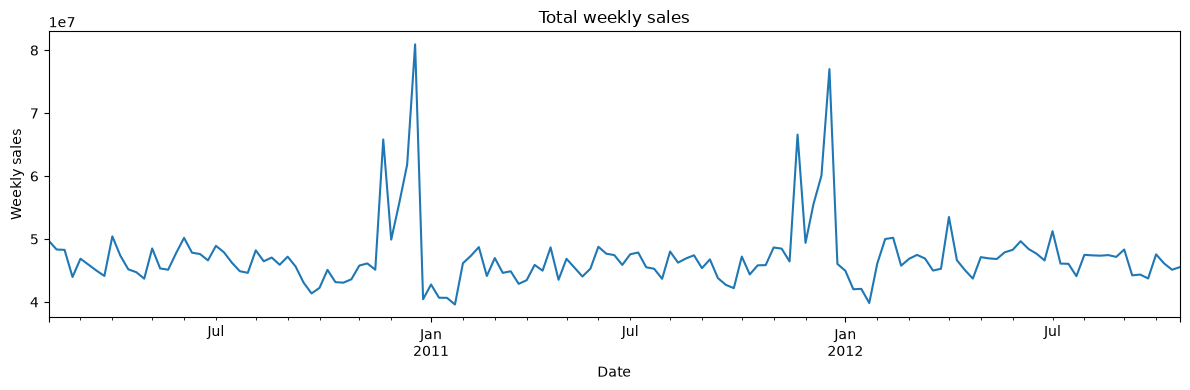

,count,mean,median,std
Type,,,,
A,215478,20099.568043,10105.17,26423.457227
B,163495,12237.075977,6187.87,17203.668989
C,42597,9519.532538,1149.67,15985.351612


,count,mean,median,sum
IsHoliday,,,,
False,391909,15901.445069,7589.95,6.231919e+09
True,29661,17035.823187,7947.74,5.052996e+08


In [4]:
weekly = df.groupby('Date').Weekly_Sales.sum().sort_index()
plt.figure(figsize=(12,4)); weekly.plot(); plt.title('Total weekly sales'); plt.xlabel('Date'); plt.ylabel('Weekly sales'); plt.tight_layout(); plt.show()
display(df.groupby('Type').Weekly_Sales.agg(['count','mean','median','std']).sort_values('mean',ascending=False))
display(df.groupby('IsHoliday').Weekly_Sales.agg(['count','mean','median','sum']))

## 4. Anomaly detection
A rolling median/MAD score is calculated separately within each Store–Department series using only prior weeks. A flag means “investigate,” not “delete.” Compare flagged weeks with holiday flags, markdowns, nearby weeks and source records.

Anomaly candidates: 15,793 (3.75%)


,Store,Dept,Date,Weekly_Sales,IsHoliday,MarkDown1,robust_z
36,1,1,2010-10-15,26978.34,False,0.00,5.640030
37,1,1,2010-10-22,25543.04,False,0.00,4.536256
38,1,1,2010-10-29,38640.93,False,0.00,7.734231
39,1,1,2010-11-05,34238.88,False,0.00,5.541140
45,1,1,2010-12-17,44912.86,False,0.00,4.992686
53,1,1,2011-02-11,37887.17,True,0.00,5.103910
63,1,1,2011-04-22,50510.31,False,0.00,9.442880
64,1,1,2011-04-29,41512.39,False,0.00,6.447970
91,1,1,2011-11-04,39886.06,False,0.00,6.234043
113,1,1,2012-04-06,57592.12,False,10121.97,7.260665


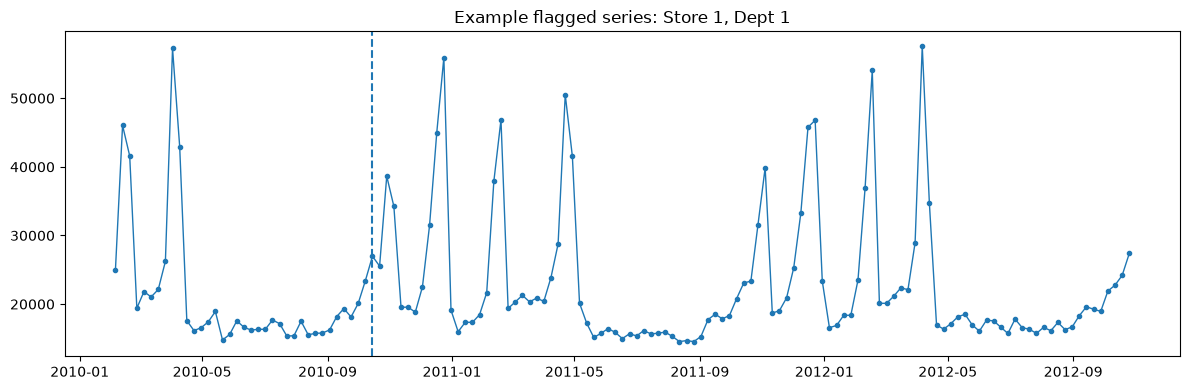

In [5]:
flagged = df[df.anomaly_flag].copy()
print(f'Anomaly candidates: {len(flagged):,} ({len(flagged)/len(df):.2%})')
display(flagged[['Store','Dept','Date','Weekly_Sales','IsHoliday','MarkDown1','robust_z']].head(25))
if len(flagged):
    r = flagged.iloc[0]
    series = df[(df.Store==r.Store)&(df.Dept==r.Dept)].sort_values('Date')
    plt.figure(figsize=(12,4)); plt.plot(series.Date,series.Weekly_Sales,marker='.',linewidth=1); plt.axvline(r.Date,linestyle='--')
    plt.title(f'Example flagged series: Store {r.Store}, Dept {r.Dept}'); plt.tight_layout(); plt.show()

## 5. Store-department segmentation
These are operational profiles, not customer personas. KMeans is applied to standardized sales level, variability, markdown and holiday features. Silhouette evaluates separation in feature space, but interpretability and temporal stability also matter.

In [6]:
seg = pd.read_csv(ROOT/'reports'/'segment_profiles.csv')
metrics = json.loads((ROOT/'reports'/'model_metrics.json').read_text())
print('Silhouette by k:', metrics['silhouette_by_k'], '| selected k:', metrics['selected_k'])
display(seg.groupby('Segment').agg(profile_count=('Dept','size'),mean_sales=('mean_sales','mean'),
    volatility=('sales_std','mean'),avg_cv=('sales_cv','mean'),holiday_lift=('holiday_lift','mean'),
    markdown_mean=('markdown_mean','mean')).round(3).sort_values('mean_sales',ascending=False))

Silhouette by k: {'2': 0.30324070507429673, '3': 0.36396820423346365, '4': 0.3647526180640889, '5': 0.369272931636322, '6': 0.38378583928972027} | selected k: 6


,profile_count,mean_sales,volatility,avg_cv,holiday_lift,markdown_mean
Segment,,,,,,
2,384,60107.272,12566.119,2.530000e-01,1.090,3244.004
4,1795,10263.542,3129.656,4.890000e-01,1.111,3434.814
0,1087,5256.043,1242.848,5.630000e-01,1.069,862.054
1,60,22.562,187.672,1.078000e+01,1.262,2480.450
5,3,0.000,19.200,1.920031e+07,NaN,233.283
3,2,-2.165,214.660,1.186000e+02,194.194,4094.312


## 6. Market basket analysis: data limitation and proxy
No transaction-level baskets or product IDs exist in these inputs, so Apriori/FP-Growth support, confidence and lift are not computable. The supplied proxy is correlation of weekly sales between departments within a store. Correlation may reflect common holidays or store traffic and is not proof of joint purchases.

In [7]:
assoc_path = ROOT/'reports'/'department_sales_comovement_proxy_top1000.csv'
if assoc_path.exists():
    display(pd.read_csv(assoc_path).head(25))
else:
    print('Run src/run_pipeline.py to generate department co-movement proxy output.')

,Store,Dept_A,Dept_B,Sales_Correlation
0,28,91,97,0.981836
1,28,92,93,0.976309
2,13,24,33,0.970618
3,36,90,92,0.970270
4,28,90,92,0.969428
5,10,24,33,0.966427
6,4,24,33,0.966224
7,1,24,33,0.965834
8,36,81,92,0.960580
9,36,81,90,0.959798


## 7. Demand forecasting
A gradient-boosted tree uses lagged sales, shifted rolling statistics, store/dept attributes, calendar variables, holidays, markdowns and economic features. The latest 12 weeks are held out chronologically. Random splits are avoided because they can leak future patterns into training.

{
  "cutoff": "2012-08-03",
  "test_start": "2012-08-10",
  "test_end": "2012-10-26",
  "n_train": 379398,
  "n_test": 35547,
  "MAE": 1249.882506256871,
  "RMSE": 2640.57950667186,
  "WAPE": 0.08014189348025437
}


,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
9904,13,3,2012-09-07,114230.60,56059.312609,58171.287391
23207,28,92,2012-09-07,153061.49,99426.797809,53634.692191
12526,16,9,2012-10-19,111246.19,59407.839067,51838.350933
11388,14,72,2012-10-19,69389.31,118670.509279,49281.199279
16410,20,72,2012-10-19,63571.41,111252.838599,47681.428599
11389,14,72,2012-10-26,63071.17,110188.766431,47117.596431
30417,39,3,2012-09-07,27998.09,72245.721123,44247.631123
9905,13,3,2012-09-14,37384.66,77012.378597,39627.718597
9926,13,5,2012-08-24,73550.30,34104.599528,39445.700472
23219,28,93,2012-09-07,84960.92,46462.675186,38498.244814


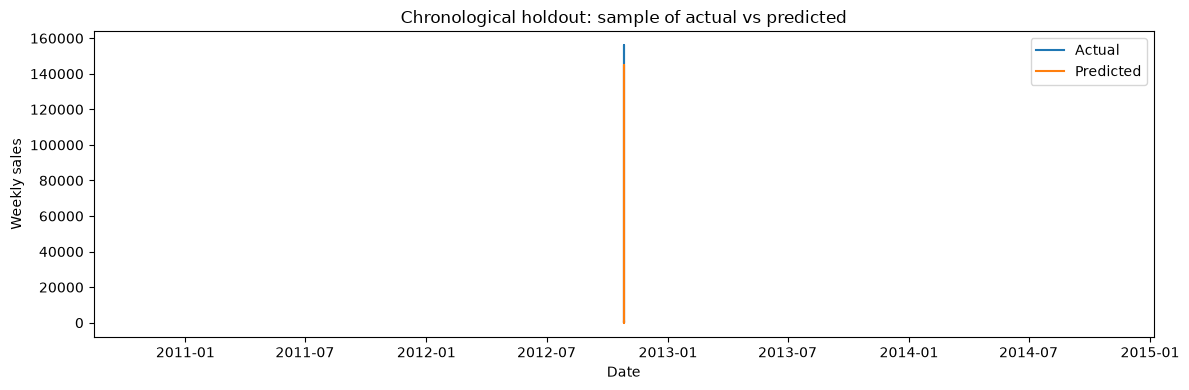

In [8]:
metrics = json.loads((ROOT/'reports'/'model_metrics.json').read_text())
print(json.dumps(metrics['forecast'],indent=2))
forecast = pd.read_csv(ROOT/'reports'/'forecast_predictions.csv',parse_dates=['Date'])
display(forecast.sort_values('Absolute_Error',ascending=False).head(15))
sample = forecast.sort_values('Date').tail(300)
plt.figure(figsize=(12,4)); plt.plot(sample.Date,sample.Weekly_Sales,label='Actual'); plt.plot(sample.Date,sample.Predicted_Sales,label='Predicted')
plt.title('Chronological holdout: sample of actual vs predicted'); plt.xlabel('Date'); plt.ylabel('Weekly sales'); plt.legend(); plt.tight_layout(); plt.show()

## 8. External factors
CPI, unemployment, fuel price, temperature, markdowns and holiday indicators can help prediction. Correlation or feature importance is not causal evidence. Check when each feature would actually be known at forecast time; avoid using future information.

,correlation_with_sales
Weekly_Sales,1.000000
Size,0.243828
MarkDown5,0.050465
MarkDown1,0.047172
MarkDown3,0.038562
MarkDown4,0.037467
MarkDown2,0.020716
Fuel_Price,-0.000120
Temperature,-0.002312
CPI,-0.020921


IsHoliday,False,True
Month,,
1,14126.075111,NaN
2,15885.457253,16377.996441
3,15416.657597,NaN
4,15650.338357,NaN
5,15776.337202,NaN
6,16326.137002,NaN
7,15861.419650,NaN
8,16062.516933,NaN
9,14859.674828,15881.693339


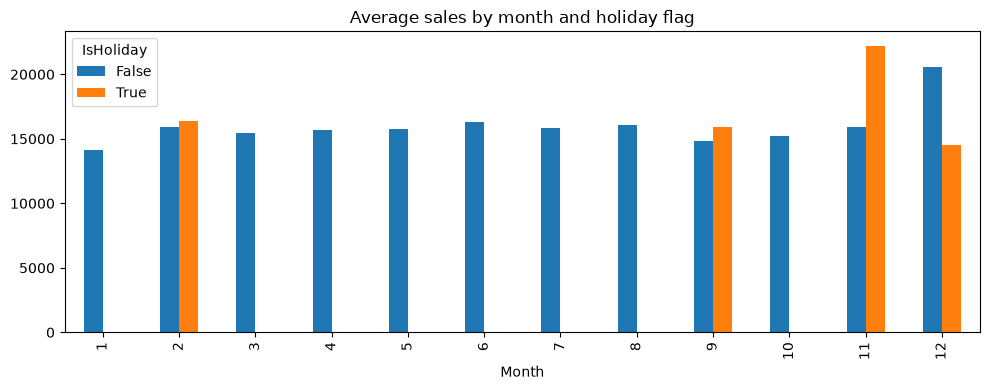

In [9]:
drivers = [c for c in ['Weekly_Sales','Temperature','Fuel_Price','CPI','Unemployment','MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5','Size'] if c in df]
display(df[drivers].corr(numeric_only=True)['Weekly_Sales'].sort_values(ascending=False).to_frame('correlation_with_sales'))
monthly_holiday = df.groupby(['Month','IsHoliday']).Weekly_Sales.mean().unstack()
display(monthly_holiday)
monthly_holiday.plot(kind='bar',figsize=(10,4),title='Average sales by month and holiday flag'); plt.tight_layout(); plt.show()

## 9. Business recommendations
1. Use forecasts as inputs to replenishment, combined with supplier lead time, minimum order quantities, and desired service levels.
2. Send anomaly candidates to an investigation queue enriched with holiday and markdown context; never delete automatically.
3. High-volume stable profiles can use more standardized replenishment; volatile profiles need tighter review and flexible safety stock.
4. Test markdown and cross-merchandising hypotheses with controlled experiments; do not interpret correlation as causation.
5. Obtain transaction and SKU-level data before true market basket analysis or customer personalization.
6. Monitor forecast error and data drift by store and department, retrain on a planned cadence, and use rolling-origin backtesting plus seasonal-naive benchmarks.

## 10. Evaluation, limitations, and next steps
- Forecast metrics: MAE, RMSE, WAPE on a chronological holdout; compare to seasonal-naive benchmarks before deployment.
- Segmentation: silhouette across candidate k values plus business interpretability; assess stability across time.
- Anomaly detection: no labelled ground truth exists, so precision/recall cannot honestly be reported without reviewed labels.
- Association: co-movement proxy only; actual market basket rules require transaction line data.
- Improve with rolling-origin validation, prediction intervals, store/dept error analysis, richer regional climate data, causal markdown experiments, and transaction-level baskets.



In [10]:
df = sales_raw.merge(
    stores,
    on="Store",
    how="left",
    validate="many_to_one"
)

df = df.merge(
    features_raw,
    on=["Store", "Date"],
    how="left",
    suffixes=("", "_feature"),
    validate="many_to_one"
)

In [11]:
df["MarkDown1_was_missing"] = (
    df["MarkDown1"].isna().astype(int)
)

df["MarkDown1"] = df["MarkDown1"].fillna(0)

In [12]:
print(df["Date"].dtype)

str


In [13]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)


In [14]:
print(df["Date"].dtype)

datetime64[us]


In [15]:
df["Year"] = df["Date"].dt.year

df["Month"] = df["Date"].dt.month

df["WeekOfYear"] = (
    df["Date"].dt.isocalendar().week
)

In [16]:
df[["Date", "Year", "Month", "WeekOfYear"]].head(10)

,Date,Year,Month,WeekOfYear
0,2010-02-05,2010,2,5
1,2010-02-12,2010,2,6
2,2010-02-19,2010,2,7
3,2010-02-26,2010,2,8
4,2010-03-05,2010,3,9
5,2010-03-12,2010,3,10
6,2010-03-19,2010,3,11
7,2010-03-26,2010,3,12
8,2010-04-02,2010,4,13
9,2010-04-09,2010,4,14


In [17]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

print(df[markdown_cols].head())

   MarkDown1  MarkDown2  MarkDown3  MarkDown4  MarkDown5
0        0.0        NaN        NaN        NaN        NaN
1        0.0        NaN        NaN        NaN        NaN
2        0.0        NaN        NaN        NaN        NaN
3        0.0        NaN        NaN        NaN        NaN
4        0.0        NaN        NaN        NaN        NaN


In [18]:
df[markdown_cols].isnull().sum()
df[markdown_cols].isnull().mean() * 100

MarkDown1     0.000000
MarkDown2    73.611025
MarkDown3    67.480845
MarkDown4    67.984676
MarkDown5    64.079038
dtype: float64

In [19]:
for col in markdown_cols:
    df[col + "_was_missing"] = df[col].isna()

In [20]:
df[markdown_cols] = df[markdown_cols].fillna(0)

In [21]:
weekly = (
    df.groupby('Date')['Weekly_Sales']
      .sum()
      .sort_index()
)

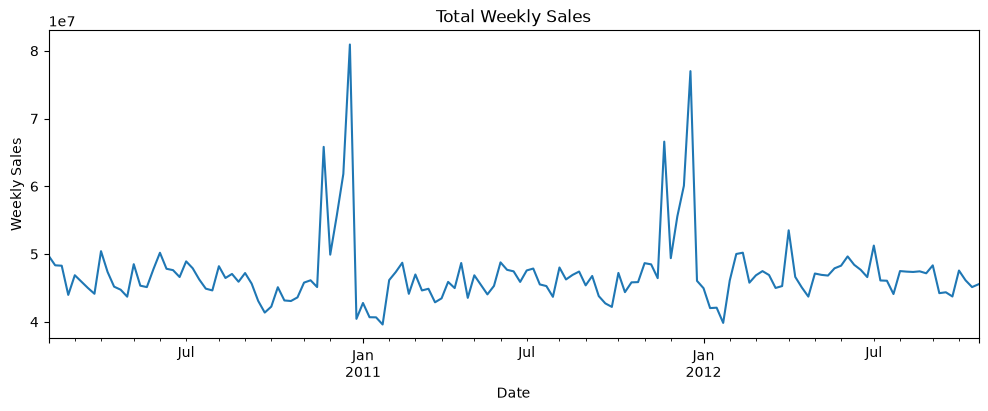

In [22]:
weekly.plot(figsize=(12, 4))

plt.title('Total Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')

plt.show()

In [23]:
df.groupby('Type')['Weekly_Sales'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Type,,,,
A,215478,20099.568043,10105.17,26423.457227
B,163495,12237.075977,6187.87,17203.668989
C,42597,9519.532538,1149.67,15985.351612


In [24]:
df.groupby('IsHoliday')['Weekly_Sales'].agg(
    ['count', 'mean', 'median', 'sum']
)

,count,mean,median,sum
IsHoliday,,,,
False,391909,15901.445069,7589.95,6.231919e+09
True,29661,17035.823187,7947.74,5.052996e+08


In [25]:
display(
    flagged[
        [
            'Store',
            'Dept',
            'Date',
            'Weekly_Sales',
            'IsHoliday',
            'MarkDown1',
            'robust_z'
        ]
    ].head(25)
)


,Store,Dept,Date,Weekly_Sales,IsHoliday,MarkDown1,robust_z
36,1,1,2010-10-15,26978.34,False,0.00,5.640030
37,1,1,2010-10-22,25543.04,False,0.00,4.536256
38,1,1,2010-10-29,38640.93,False,0.00,7.734231
39,1,1,2010-11-05,34238.88,False,0.00,5.541140
45,1,1,2010-12-17,44912.86,False,0.00,4.992686
53,1,1,2011-02-11,37887.17,True,0.00,5.103910
63,1,1,2011-04-22,50510.31,False,0.00,9.442880
64,1,1,2011-04-29,41512.39,False,0.00,6.447970
91,1,1,2011-11-04,39886.06,False,0.00,6.234043
113,1,1,2012-04-06,57592.12,False,10121.97,7.260665


In [31]:
import os

print("Current working directory:")
print(os.getcwd())


Current working directory:
c:\Users\kmkb5\Downloads\retail_analytics_submission\notebooks


In [32]:
from pathlib import Path

print("Expected reports path:")
print(Path("reports").resolve())

print("Does reports folder exist?")
print(Path("reports").exists())

Expected reports path:
C:\Users\kmkb5\Downloads\retail_analytics_submission\notebooks\reports
Does reports folder exist?
False


In [33]:
from pathlib import Path

current = Path.cwd()

print("Current folder:", current)
print("Parent folder:", current.parent)

print("Files in current folder:")
print(list(current.iterdir()))

Current folder: c:\Users\kmkb5\Downloads\retail_analytics_submission\notebooks
Parent folder: c:\Users\kmkb5\Downloads\retail_analytics_submission
Files in current folder:
[WindowsPath('c:/Users/kmkb5/Downloads/retail_analytics_submission/notebooks/retail_analytics_capstone.ipynb')]


In [34]:
with open("../reports/model_metrics.json", "r") as file:
    metrics = json.load(file)

print(json.dumps(metrics, indent=4))

{
    "forecast": {
        "cutoff": "2012-08-03",
        "test_start": "2012-08-10",
        "test_end": "2012-10-26",
        "n_train": 379398,
        "n_test": 35547,
        "MAE": 1249.882506256871,
        "RMSE": 2640.57950667186,
        "WAPE": 0.08014189348025437
    },
    "silhouette_by_k": {
        "2": 0.30324070507429673,
        "3": 0.36396820423346365,
        "4": 0.3647526180640889,
        "5": 0.369272931636322,
        "6": 0.38378583928972027
    },
    "selected_k": 6,
    "anomaly_candidates": 15793
}


In [36]:
import json

with open(REPORTS_DIR / "model_metrics.json", "r") as file:
    metrics = json.load(file)

print(json.dumps(metrics, indent=4))

{
    "forecast": {
        "cutoff": "2012-08-03",
        "test_start": "2012-08-10",
        "test_end": "2012-10-26",
        "n_train": 379398,
        "n_test": 35547,
        "MAE": 1249.882506256871,
        "RMSE": 2640.57950667186,
        "WAPE": 0.08014189348025437
    },
    "silhouette_by_k": {
        "2": 0.30324070507429673,
        "3": 0.36396820423346365,
        "4": 0.3647526180640889,
        "5": 0.369272931636322,
        "6": 0.38378583928972027
    },
    "selected_k": 6,
    "anomaly_candidates": 15793
}


In [37]:
from pathlib import Path

REPORTS_DIR = Path("../reports")

expected_reports = [
    "model_metrics.json",
    "anomaly_flags.csv",
    "segment_summary.csv",
    "segment_profiles.csv",
    "forecast_predictions.csv",
    "department_sales_comovement_proxy_top1000.csv"
]

for report in expected_reports:
    path = REPORTS_DIR / report
    print(
        report,
        " : ",
        "Available" if path.exists() else "Missing"
    )

model_metrics.json  :  Available
anomaly_flags.csv  :  Available
segment_summary.csv  :  Available
segment_profiles.csv  :  Available
forecast_predictions.csv  :  Available
department_sales_comovement_proxy_top1000.csv  :  Available


In [38]:
MODELS_DIR = Path("../models")

for model in MODELS_DIR.glob("*"):
    print(model.name, model.stat().st_size, "bytes")
    

store_department_segmentation.joblib 15916 bytes
weekly_sales_forecaster.joblib 472214 bytes


In [39]:
import pandas as pd

forecast = pd.read_csv(
    "../reports/forecast_predictions.csv"
)

print("Forecast records:", len(forecast))
print("Missing values:")
print(forecast.isnull().sum())

display(forecast.head())

Forecast records: 35547
Missing values:
Store              0
Dept               0
Date               0
Weekly_Sales       0
Predicted_Sales    0
Absolute_Error     0
dtype: int64


,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
0,1,1,2012-08-10,16119.92,16599.598578,479.678578
1,1,1,2012-08-17,17330.70,15858.723651,1471.976349
2,1,1,2012-08-24,16286.40,16864.961307,578.561307
3,1,1,2012-08-31,16680.24,16310.882411,369.357589
4,1,1,2012-09-07,18322.37,17334.231752,988.138248


Rows: 35547
Date range: 2012-08-10 00:00:00 to 2012-10-26 00:00:00
Unique dates: 12


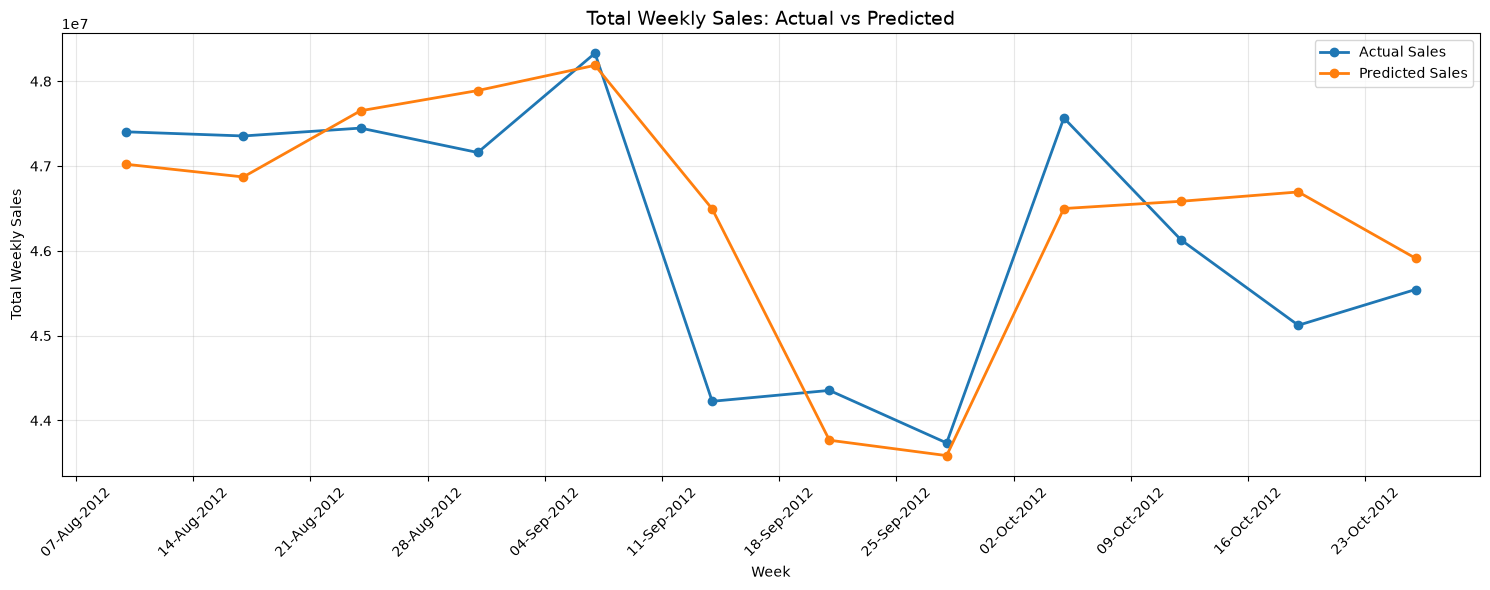

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load forecast results
forecast = pd.read_csv(
    ROOT / "reports" / "forecast_predictions.csv",
    parse_dates=["Date"]
)

# Check the date range and number of records
print("Rows:", len(forecast))
print("Date range:", forecast["Date"].min(), "to", forecast["Date"].max())
print("Unique dates:", forecast["Date"].nunique())

# Aggregate all stores and departments into one weekly total
weekly = (
    forecast.groupby("Date", as_index=False)
    .agg(
        Actual_Sales=("Weekly_Sales", "sum"),
        Predicted_Sales=("Predicted_Sales", "sum")
    )
    .sort_values("Date")
)

# Calculate error AFTER aggregation
weekly["Error"] = weekly["Actual_Sales"] - weekly["Predicted_Sales"]
weekly["Absolute_Error"] = weekly["Error"].abs()

# Plot actual vs predicted weekly sales
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    weekly["Date"], weekly["Actual_Sales"],
    label="Actual Sales", linewidth=2, marker="o"
)
ax.plot(
    weekly["Date"], weekly["Predicted_Sales"],
    label="Predicted Sales", linewidth=2, marker="o"
)

ax.set_title("Total Weekly Sales: Actual vs Predicted", fontsize=14)
ax.set_xlabel("Week")
ax.set_ylabel("Total Weekly Sales")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b-%Y"))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

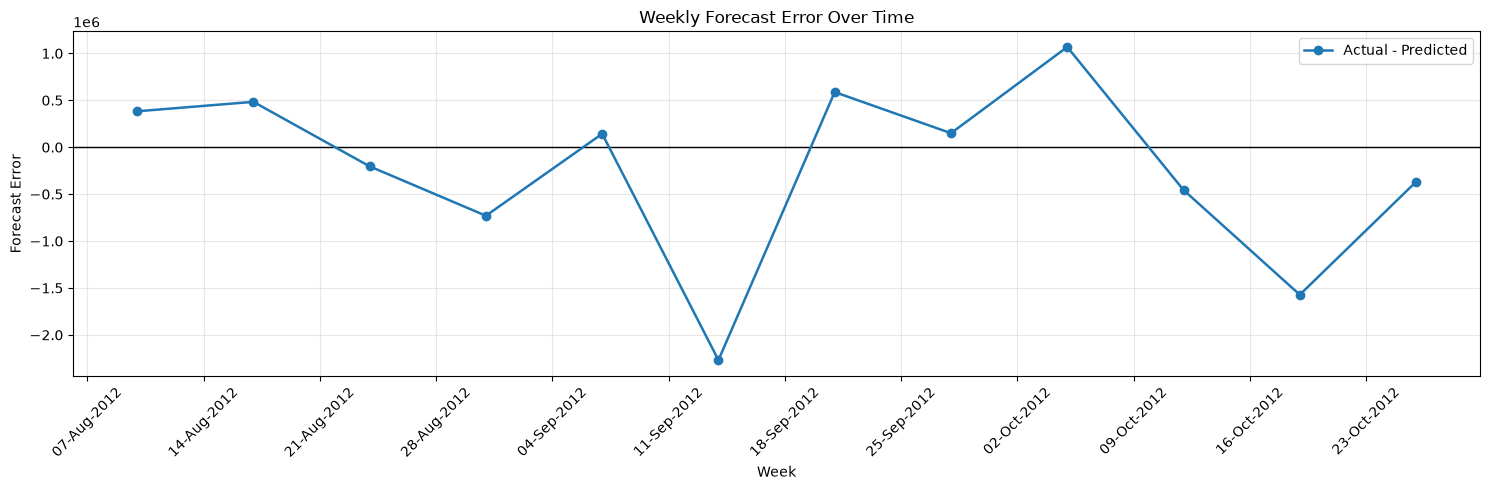

In [46]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.axhline(0, color="black", linewidth=1)
ax.plot(
    weekly["Date"], weekly["Error"],
    marker="o", linewidth=1.8, label="Actual - Predicted"
)

ax.set_title("Weekly Forecast Error Over Time")
ax.set_xlabel("Week")
ax.set_ylabel("Forecast Error")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b-%Y"))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [42]:
weekly["APE_Percent"] = (
    weekly["Absolute_Error"] /
    weekly["Actual_Sales"].replace(0, pd.NA)
) * 100

print("Worst 10 weeks by absolute error:")

display(
    weekly.sort_values("Absolute_Error", ascending=False)
    [["Date", "Actual_Sales", "Predicted_Sales",
      "Error", "Absolute_Error", "APE_Percent"]]
    .head(10)
)


Worst 10 weeks by absolute error:


,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error,APE_Percent
5,2012-09-14,44226007.10,4.649429e+07,-2.268284e+06,2.268284e+06,5.128847
10,2012-10-19,45122410.57,4.669444e+07,-1.572030e+06,1.572030e+06,3.483922
8,2012-10-05,47566629.05,4.649878e+07,1.067849e+06,1.067849e+06,2.244955
3,2012-08-31,47159634.96,4.789000e+07,-7.303632e+05,7.303632e+05,1.548704
6,2012-09-21,44354523.20,4.376714e+07,5.873803e+05,5.873803e+05,1.324285
1,2012-08-17,47354481.05,4.687112e+07,4.833634e+05,4.833634e+05,1.020734
9,2012-10-12,46128484.37,4.658439e+07,-4.559021e+05,4.559021e+05,0.988331
0,2012-08-10,47403421.16,4.702091e+07,3.825088e+05,3.825088e+05,0.806922
11,2012-10-26,45544132.92,4.591285e+07,-3.687160e+05,3.687160e+05,0.809580
2,2012-08-24,47447279.72,4.765145e+07,-2.041732e+05,2.041732e+05,0.430316


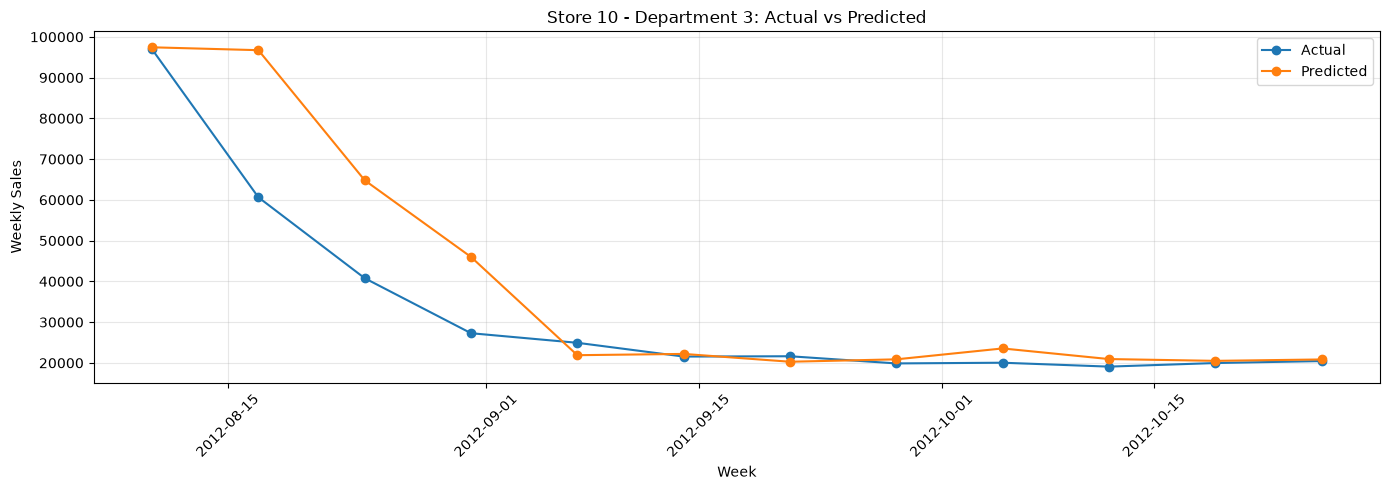

In [ ]:
# Select a store and department
store_id = 10
dept_id = 3

single_series = forecast[
    (forecast["Store"] == store_id) &
    (forecast["Dept"] == dept_id)
].sort_values("Date")

plt.figure(figsize=(14, 5))

plt.plot(
    single_series["Date"],
    single_series["Weekly_Sales"],
    marker="o",
    label="Actual"
)

plt.plot(
    single_series["Date"],
    single_series["Predicted_Sales"],
    marker="o",
    label="Predicted"
)

plt.title(f"Store {store_id} - Department {dept_id}: Actual vs Predicted")
plt.xlabel("Week")
plt.ylabel("Weekly Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()